# GIFTERS: interrogating local Qwen3-0.6B
University of Toronto · AI Forensics

Three experiments: **generalizability** (observed-token likelihood), **robustness** (input changes), and **stability** (local weight changes). Run cells in order with the existing `Agentic_Workflow_Build` Python environment. Qwen3-0.6B is loaded once in float32; the existing frozen MiniLM encoder is retained. All inference stays local and offline.

Choose `settings_for('fast')` or `settings_for('extended')` below. Fast uses eight responses per ensemble, 20 independent baseline pairs, and a 3×3 weight grid; extended increases ensemble size and baseline sampling before grid resolution. The notebook profiles local response generation and reports a conservative runtime estimate before expensive execution, with a 3.8-hour session budget. Runtime depends on prompt length and hardware; checkpointed reruns reuse completed samples.

The generalizability experiment is unchanged. Robustness now combines Qwen paraphrases with generic deterministic surface edits. Statistical comparisons remain exploratory: a high baseline percentile is not a formal significance claim.

**Validation:** default configuration completed locally with 872 responses, 18 unique input variants and nine weight settings. Main execution: 28 minutes; checkpoint replay with the final added paraphrase: 32 seconds. All weight restoration checks passed. The extended preset subsequently completed, including the padding addition in Section 2b. See `GEMMA_GIFTERS_README.md` for detailed timing and limitations.

Section **2b** adds token-padding robustness: correctly masked versus intentionally attended left padding, plus an independent zero-padding diagnostic. It uses the same local model, frozen encoder, response-centroid metric and baseline methodology. The total runtime estimate now includes these extra responses.

**Padding validation:** 360 sampled responses across 30 conditions; 29 conditions have complete semantic-distance measurements. Five responses at 128 attended pads for the second prompt reached the generation cap, so that condition reports failures instead of a partial-ensemble distance. Padding took 16.5 minutes; a complete cached notebook replay took 21 seconds with zero new generations.

In [1]:
import os, json, time, hashlib, importlib.metadata, urllib.request, re, difflib
from pathlib import Path
from contextlib import contextmanager
from dataclasses import dataclass, asdict
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
SESSION_START = time.perf_counter()

@dataclass
class Settings:
    mode: str = 'fast'
    backend: str = 'transformers'
    model: str = 'models/Qwen3-0.6B'
    encoder_path: str = '/Users/jae3goals/Jupyter Code on Root/MAT186/.models/all-MiniLM-L6-v2'
    temperature: float = 0.7
    ensemble_size: int = 8
    baseline_pairs: int = 20  # 40 independent ensembles per distinct original prompt
    max_new_tokens: int = 256
    max_document_tokens: int = 192
    seed: int = 420
    variants_per_type: int = 2
    perturbation_types: tuple = ('paraphrase','spelling','punctuation','formatting','reorder')
    magnitudes: tuple = (0.15, 0.30)  # requested surface edit fractions; method-specific
    paraphrase_attempts: int = 4
    grid_size: int = 3
    weight_radius: float = 0.005
    device: str = 'cpu'
    plane_max_parameters: int = 1_500_000_000
    response_instruction: str = 'Answer in at most 30 words, in one paragraph without headings. Include the requested limitation or significance.'
    runtime_budget_hours: float = 3.8
    padding_enabled: bool = True
    padding_counts: tuple = (0,1,8,32)
    padding_modes: tuple = ('masked','attended')
    paired_sampling: bool = False  # optional secondary paired diagnostic; independent baseline retained

def settings_for(mode):
    if mode == 'fast': return Settings()
    if mode == 'extended':
        return Settings(mode=mode, ensemble_size=12, baseline_pairs=32, variants_per_type=3,
                        magnitudes=(0.1,0.2,0.3), padding_counts=(0,1,2,4,8,16,32,128))  # keep 3×3: prioritize ensembles
    raise ValueError('Choose fast or extended')

cfg = settings_for('extended')  # choose 'fast' or 'extended'; override individual fields below
assert cfg.ensemble_size >= 2 and cfg.baseline_pairs >= 2 and cfg.temperature > 0
assert cfg.grid_size >= 3 and cfg.grid_size % 2 == 1
assert cfg.variants_per_type > 0 and all(0 < m <= 1 for m in cfg.magnitudes)
assert set(cfg.perturbation_types) <= {'paraphrase','spelling','punctuation','formatting','reorder'}
OUT = Path('gifters_results') / (datetime.now(ZoneInfo('America/Toronto')).strftime('%Y%m%d-%H%M%S')+'-'+cfg.mode)
OUT.mkdir(parents=True, exist_ok=True)
CACHE = Path('gifters_results/checkpoints_v2'); CACHE.mkdir(parents=True, exist_ok=True)
status = {}; timings = {}; cache_stats = {'generation_hits':0,'generation_misses':0,'embedding_hits':0}
versions = {p:importlib.metadata.version(p) for p in ['torch','transformers','numpy','pandas','matplotlib','sentence-transformers']}
def atomic_json(path, value):
    path=Path(path); tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(value,indent=2,ensure_ascii=False,allow_nan=False)); tmp.replace(path)
def digest(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def seed_for(*parts):
    return int(digest([cfg.seed,*parts])[:15],16)  # stable 60-bit seed, independent of traversal order

def file_fingerprint(root):
    result={}
    for f in sorted(Path(root).rglob('*')):
        if f.is_file() and '.cache' not in f.parts and f.suffix in {'.json','.safetensors','.txt','.jinja'}:
            h=hashlib.sha256()
            with f.open('rb') as stream:
                for chunk in iter(lambda:stream.read(8*1024*1024),b''): h.update(chunk)
            result[str(f.relative_to(root))]=h.hexdigest()
    return digest(result)
MODEL_ID=file_fingerprint(cfg.model); ENCODER_ID=file_fingerprint(cfg.encoder_path)
# Bump when changing generation semantics, including chat template or stopping behavior.
ENGINE_ID=digest({'revision':'gifters-v2','model':MODEL_ID,'versions':versions,
                  'device':cfg.device,'dtype':'float32','threads':4,'thinking':False,'top_p':1.0,'top_k':0})
atomic_json(OUT/'config.json',asdict(cfg)); atomic_json(OUT/'versions.json',versions)
atomic_json(OUT/'identities.json',{'model':MODEL_ID,'encoder':ENCODER_ID,'engine':ENGINE_ID})
print('Results:',OUT.resolve(),'\nReusable checkpoints:',CACHE.resolve())
display(pd.Series(asdict(cfg)))
assert len(set(cfg.padding_counts))==len(cfg.padding_counts) and 0 in cfg.padding_counts
assert all(isinstance(k,int) and k>=0 for k in cfg.padding_counts)
assert set(cfg.padding_modes)<= {'masked','attended'} and cfg.padding_modes


/Users/jae3goals/anaconda3/envs/Agentic_Workflow_Build/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Results: /Users/jae3goals/Jupyter Code on Root/MSE420_1020_AI_Forensics/MSE420_AI_Forensics/demonstrations/gifters_results/20261105-112738-extended 
Reusable checkpoints: /Users/jae3goals/Jupyter Code on Root/MSE420_1020_AI_Forensics/MSE420_AI_Forensics/demonstrations/gifters_results/checkpoints_v2


mode                                                             extended
backend                                                      transformers
model                                                   models/Qwen3-0.6B
encoder_path            /Users/jae3goals/Jupyter Code on Root/MAT186/....
temperature                                                           0.7
ensemble_size                                                          12
baseline_pairs                                                         32
max_new_tokens                                                        256
max_document_tokens                                                   192
seed                                                                  420
variants_per_type                                                       3
perturbation_types      (paraphrase, spelling, punctuation, formatting...
magnitudes                                                (0.1, 0.2, 0.3)
paraphrase_attempts                   

In [2]:
def ollama_api(endpoint, payload=None):
    # Fixed loopback endpoint; proxies cannot redirect local inference.
    request = urllib.request.Request('http://127.0.0.1:11434/api/' + endpoint,
        data=None if payload is None else json.dumps(payload).encode(),
        headers={'Content-Type':'application/json'})
    with urllib.request.build_opener(urllib.request.ProxyHandler({})).open(request, timeout=600) as r:
        return json.load(r)

inventory = {'hf_snapshots': []}
for p in (Path.home()/'.cache/huggingface/hub').glob('models--*/snapshots/*'):
    inventory['hf_snapshots'].append({'path':str(p), 'weights':bool(list(p.glob('*.safetensors')) or list(p.glob('pytorch_model*.bin')))})
inventory['active_model'] = cfg.model  # no network or Ollama request needed
(OUT/'inventory.json').write_text(json.dumps(inventory, indent=2))
display(inventory)

class OllamaBackend:
    editable = False
    def __init__(self, name):
        self.name = name
        info = ollama_api('show', {'model':name})
        if info.get('remote_host') or info.get('remote_model') or 'cloud' in name:
            raise ValueError('Only local models are permitted')
        if 'gemma' not in str(info.get('details', {})).lower():
            raise ValueError('Select an installed Gemma model')
        (OUT/'model_info.json').write_text(json.dumps(info, indent=2))
    def generate(self, prompt, seed, temperature=None):
        result = ollama_api('chat', {'model':self.name, 'stream':False, 'think':False,
            'messages':[{'role':'user','content':prompt}],
            'options':{'temperature':cfg.temperature if temperature is None else temperature,
                       'seed':int(seed),'num_predict':cfg.max_new_tokens,'num_ctx':2048, 'top_k':0, 'top_p':1.0}})
        if result.get('done_reason') == 'length':
            raise RuntimeError('Response hit token cap; increase max_new_tokens or shorten response_instruction and rerun')
        text = result['message']['content'].strip()
        if not text: raise RuntimeError('Empty response; increase token budget or inspect model thinking settings')
        return text

class TransformersBackend:
    editable = True
    def __init__(self, path):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch = torch
        torch.set_num_threads(4)
        self.tokenizer = AutoTokenizer.from_pretrained(path, local_files_only=True)
        self.model = AutoModelForCausalLM.from_pretrained(path, local_files_only=True,
            dtype=torch.float32).to(cfg.device).eval()
        if self.model.config.model_type not in {'qwen3','gemma','gemma2','gemma3_text'}:
            raise ValueError('Select a supported local causal language model')
        if getattr(self.model, 'is_quantized', False):
            raise ValueError('Use floating-point weights for the plane experiment')
        for p in self.model.parameters(): p.requires_grad_(False)
        self.model.config.to_json_file(str(OUT/'model_config.json'))
    def generate(self, prompt, seed, temperature=None):
        t = self.torch; t.manual_seed(int(seed))
        if cfg.device == 'mps': t.mps.manual_seed(int(seed))
        tok = self.tokenizer
        if tok.chat_template:
            prompt = tok.apply_chat_template([{'role':'user','content':prompt}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
            x = tok(prompt, return_tensors='pt', add_special_tokens=False).to(cfg.device)
        else: x = tok(prompt, return_tensors='pt').to(cfg.device)
        with t.inference_mode():
            y = self.model.generate(**x, do_sample=True,
                temperature=cfg.temperature if temperature is None else temperature,
                top_p=1.0, top_k=0, max_new_tokens=cfg.max_new_tokens,
                pad_token_id=tok.eos_token_id)
        new_tokens = y[0,x.input_ids.shape[1]:]
        eos = self.model.generation_config.eos_token_id
        eos = [eos] if isinstance(eos,int) else (eos or [])
        if len(new_tokens) >= cfg.max_new_tokens and int(new_tokens[-1]) not in eos:
            raise RuntimeError('Generation hit token cap; shorten answer instruction or raise max_new_tokens')
        result = tok.decode(new_tokens, skip_special_tokens=True).strip()
        if not result: raise RuntimeError('Empty generated response')
        return result
    def token_losses(self, text):
        t = self.torch
        ids = self.tokenizer(text, return_tensors='pt', truncation=True,
            max_length=cfg.max_document_tokens).input_ids.to(cfg.device)
        if ids.shape[1] < 2: raise ValueError('Document needs at least two tokens')
        with t.inference_mode():
            logits = self.model(input_ids=ids, use_cache=False).logits[0,:-1].float()
            losses = t.nn.functional.cross_entropy(logits, ids[0,1:], reduction='none')
        return self.tokenizer.convert_ids_to_tokens(ids[0,1:].tolist()), losses.cpu().numpy()

LOAD_START=time.perf_counter()
backend = None; encoder = None
try:
    backend = OllamaBackend(cfg.model) if cfg.backend == 'ollama' else TransformersBackend(cfg.model)
    status['generation'] = 'READY'
except Exception as e: status['generation'] = 'BLOCKED: ' + str(e)
try:
    if not cfg.encoder_path: raise ValueError('Set encoder_path to a local sentence embedding model')
    from sentence_transformers import SentenceTransformer
    if (Path(cfg.encoder_path)/'modules.json').exists():
        encoder = SentenceTransformer(cfg.encoder_path, local_files_only=True, device='cpu').eval()
    else:
        # Existing MAT186 export has the transformer weights, but no pooling metadata.
        # Reconstruct MiniLM's attention-mask-aware mean pooling explicitly.
        from sentence_transformers import models
        transformer = models.Transformer(cfg.encoder_path, max_seq_length=256,
            model_args={'local_files_only':True}, tokenizer_args={'local_files_only':True})
        pooling = models.Pooling(transformer.get_word_embedding_dimension(), pooling_mode='mean')
        encoder = SentenceTransformer(modules=[transformer,pooling], device='cpu').eval()
    (OUT/'encoder_info.json').write_text(json.dumps({'path':cfg.encoder_path,
        'max_seq_length':encoder.max_seq_length,'pooling':'mean','normalized':True},indent=2))
    for p in encoder.parameters(): p.requires_grad_(False)
except Exception as e: status['encoder'] = 'BLOCKED: ' + str(e)
else: status['encoder'] = 'READY'
display(status)
if backend is None or encoder is None: raise RuntimeError(status)
timings['model_and_encoder_load_seconds']=time.perf_counter()-LOAD_START

{'hf_snapshots': [{'path': '/Users/jae3goals/.cache/huggingface/hub/models--google--gemma-4-26B-A4B-it/snapshots/4d7ae4984b7db7de8f8457170b3f1a419ee76d52',
   'weights': False}],
 'active_model': 'models/Qwen3-0.6B'}

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:  95%|█████████▌| 296/311 [00:00<00:00, 2940.94it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 2773.12it/s]

/var/folders/4_/gyyynsks73b0myq8_fknp0680000gn/T/ipykernel_2109/491860504.py:98: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models
The Transformer `model_args` argument was renamed and is now deprecated, please use `model_kwargs` instead.


The Transformer `tokenizer_args` argument was renamed and is now deprecated, please use `processor_kwargs` instead.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 21685.24it/s]

/var/folders/4_/gyyynsks73b0myq8_fknp0680000gn/T/ipykernel_2109/491860504.py:101: FutureWarning: The `get_word_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  pooling = models.Pooling(transformer.get_word_embedding_dimension(), pooling_mode='mean')


{'generation': 'READY', 'encoder': 'READY'}

## 1 · Generalizability: predicting observed text
These six **instructor-style synthetic passages**, written for this exercise, are not published literature or a representative corpus. Replace them with UTF-8 `.txt` documents below (with permission), recording provenance and group labels. Each document is scored as plain text, without a chat template. We cap length for speed and report only that prefix: the first token has no preceding context and is excluded. NLL is measured in natural-log units (nats); perplexity = exp(mean NLL).

Teacher forcing supplies the actual preceding tokens at every position. We never score the model's own generated continuation as though it were the document. Different vocabulary, styles, and inherent predictability can change likelihood; neither training-set membership, factual correctness nor out-of-distribution generalization follows from this comparison.

Teacher forcing:   0%|          | 0/6 [00:00<?, ?it/s]

Teacher forcing:  17%|█▋        | 1/6 [00:00<00:00,  7.41it/s]

Teacher forcing:  33%|███▎      | 2/6 [00:00<00:00,  8.64it/s]

Teacher forcing:  67%|██████▋   | 4/6 [00:00<00:00,  9.61it/s]

Teacher forcing: 100%|██████████| 6/6 [00:00<00:00, 10.03it/s]

Teacher forcing: 100%|██████████| 6/6 [00:00<00:00,  9.65it/s]

,document,group,mean_nll,tokens,perplexity
0,Diffusion,Materials science,3.891857,36,49.001804
1,Grains,Materials science,3.131262,43,22.902870
2,Heat transfer,General science,2.929313,32,18.714773
3,Phase field,Specialized materials,4.800716,43,121.597509
4,Precipitates,Specialized materials,4.075765,44,58.895542
5,Water cycle,General science,2.152588,38,8.607103


,document,group,position,token,nll
0,Water cycle,General science,0,Ġevapor,20.647152
1,Water cycle,General science,1,ates,0.268761
2,Water cycle,General science,2,Ġfrom,0.614957
3,Water cycle,General science,3,Ġthe,0.864300
4,Water cycle,General science,4,Ġsurface,1.470350
5,Water cycle,General science,5,Ġof,0.545049
6,Water cycle,General science,6,Ġlakes,7.049457
7,Water cycle,General science,7,Ġand,0.705493
8,Water cycle,General science,8,Ġoceans,1.522448
9,Water cycle,General science,9,.,1.331234


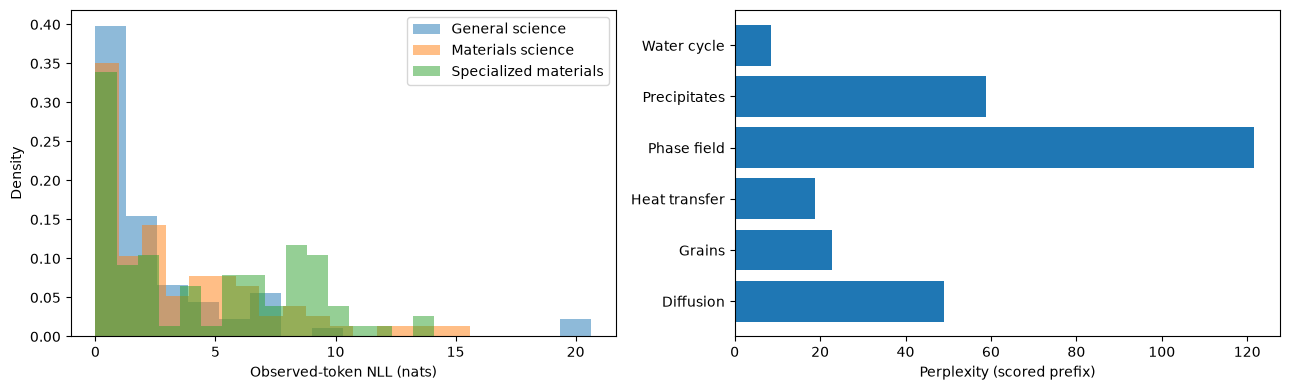

In [3]:
documents = [
 ('Water cycle','General science','Water evaporates from the surface of lakes and oceans. As moist air rises and cools, water vapor condenses into droplets. These droplets form clouds and may eventually fall as rain.'),
 ('Heat transfer','General science','Heat flows from warmer regions toward cooler regions. Conduction transfers energy through a material. Convection involves motion of a fluid, while radiation carries energy through electromagnetic waves.'),
 ('Grains','Materials science','A polycrystalline metal consists of grains with different crystallographic orientations. Grain boundaries impede dislocation motion. Reducing the average grain size often increases the yield strength, although the relationship has limits.'),
 ('Diffusion','Materials science','Atomic diffusion in a crystalline solid can proceed through vacancies. The diffusion coefficient commonly follows an Arrhenius dependence on temperature. Composition gradients drive net transport under an appropriate chemical potential gradient.'),
 ('Precipitates','Specialized materials','Coherent precipitates generate elastic misfit fields within the matrix. The competition between precipitate shearing and Orowan bypass depends on particle size, spacing, interfacial structure, and the resistance to dislocation motion.'),
 ('Phase field','Specialized materials','A Cahn–Hilliard formulation evolves a conserved composition field under gradients in variational chemical potential. Anisotropic gradient-energy coefficients and elastic coherency contributions modify interfacial morphology during spinodal decomposition.')]
# documents.append(('My paper','Specialized materials',Path('my_paper.txt').read_text()))
(OUT/'documents.json').write_text(json.dumps(documents, indent=2))
token_rows=[]
if backend is not None and backend.editable:
    for name, group, text in tqdm(documents, desc='Teacher forcing'):
        tokens, losses = backend.token_losses(text)
        token_rows.extend({'document':name,'group':group,'position':i,'token':token,'nll':float(loss)}
                          for i,(token,loss) in enumerate(zip(tokens,losses)))
    token_df=pd.DataFrame(token_rows)
    summary=token_df.groupby(['document','group']).agg(mean_nll=('nll','mean'),tokens=('nll','size')).reset_index()
    summary['perplexity']=np.exp(summary.mean_nll)
    display(summary); display(token_df.head(20))
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    for group,frame in token_df.groupby('group'):
        axs[0].hist(frame.nll, bins=16, alpha=.5, density=True,label=group)
    axs[0].set(xlabel='Observed-token NLL (nats)',ylabel='Density'); axs[0].legend()
    axs[1].barh(summary.document,summary.perplexity); axs[1].set(xlabel='Perplexity (scored prefix)')
    fig.tight_layout(); fig.savefig(OUT/'generalizability.png'); plt.show()
    token_df.to_csv(OUT/'token_losses.csv',index=False); summary.to_csv(OUT/'document_scores.csv',index=False)
    status['generalizability']='EXECUTED'
else:
    status['generalizability']='BLOCKED: teacher-forced logits require local Transformers weights'
    print(status['generalizability'])

## Shared semantic measurement and sampling uncertainty
Each response is encoded by the same frozen MiniLM model. Normalize its vector, average the response vectors, and compute cosine distance between ensemble centroids. Within-ensemble spread is the mean response-to-centroid distance. No PCA distance is used.

**Fast mode now uses 8 responses per ensemble and 20 disjoint baseline pairs (40 independently sampled ensembles) per original prompt.** Extended mode uses 12 responses and 32 pairs. A separate original anchor is used for treatments. The same prompt's baseline and anchor are reused by stability because model, temperature, encoder, instruction and sample size are identical; this saves computation, not independent evidence. The center grid point is a **new independent ensemble** and is never set to zero.

We report the empirical percentile, ratio to the baseline median, and `(1 + number of reference distances ≥ observed)/(B + 1)` as a descriptive upper-tail fraction. With 20 pairs the tail resolution is only 1/21. The 95th percentile is imprecise; a bootstrap interval for it illustrates that limitation. Treatment distances sharing an anchor are correlated; scanning many variants also creates multiple-comparison effects. These are **exploratory comparisons, not calibrated significance tests or proof of semantic equivalence**.

Independent seeds are the default. Optional paired sampling adds a *secondary* same-seed displacement against the original responses; the main metric and baseline remain independent. Matching seeds does not guarantee matching token trajectories.

Generation and embedding checkpoints are atomic and keyed by actual prompt, seed, decoding settings, model/encoder fingerprints, software versions and weight coordinates. A changed temperature produces new baseline responses. Rerunning resumes completed individual samples; model loading occurs once per kernel. No partial or failed response is reused. Checkpoints contain raw text: do not commit private prompts.

In [4]:
def cosine_distance(a,b):
    a=np.asarray(a); b=np.asarray(b)
    denom=np.linalg.norm(a)*np.linalg.norm(b)
    if denom < 1e-12: raise ValueError('Undefined cosine distance for zero centroid')
    return float(np.clip(1-np.dot(a,b)/denom,0,2))

def budget_check():
    if time.perf_counter()-SESSION_START > cfg.runtime_budget_hours*3600:
        raise RuntimeError('Session time budget reached. Checkpoints saved; rerun to resume.')

weight_state='original'; generation_events=[]; records=[]; embeddings=[]
def request_identity(prompt,seed,temperature, state=None):
    return {'engine':ENGINE_ID,'prompt':prompt,'seed':int(seed),'temperature':float(temperature),
            'max_new_tokens':cfg.max_new_tokens,'weights':weight_state if state is None else state}

def cached_generate(prompt,seed,temperature=None):
    temperature=cfg.temperature if temperature is None else temperature
    request=request_identity(prompt,seed,temperature); key=digest(request); path=CACHE/(key+'.response.json')
    if path.exists():
        saved=json.loads(path.read_text())
        if saved['request'] != request or not saved['text']: raise RuntimeError('Invalid generation checkpoint')
        cache_stats['generation_hits']+=1
        generation_events.append({'key':key,'cache_hit':True,'seconds':0})
        return saved['text']
    budget_check(); started=time.perf_counter()
    text=backend.generate(prompt,seed,temperature=temperature)
    elapsed=time.perf_counter()-started
    atomic_json(path,{'request':request,'text':text,'seconds':elapsed})
    cache_stats['generation_misses']+=1
    generation_events.append({'key':key,'cache_hit':False,'seconds':elapsed})
    atomic_json(OUT/'generation_events.json',generation_events)
    return text

def encode(texts):
    lengths=[len(encoder.tokenizer(t,truncation=False)['input_ids']) for t in texts]
    if max(lengths)>encoder.max_seq_length:
        raise ValueError('Response exceeds encoder context: reduce answer length and restart; no silent truncation')
    key=digest({'encoder':ENCODER_ID,'version':versions['sentence-transformers'],'pooling':'mean-normalized-256', 'texts':texts})
    path=CACHE/(key+'.embedding.json')
    if path.exists():
        cache_stats['embedding_hits']+=1; return np.asarray(json.loads(path.read_text()),dtype=np.float32)
    E=np.asarray(encoder.encode(texts,normalize_embeddings=True,show_progress_bar=False),dtype=np.float32)
    atomic_json(path,E.tolist()); return E

def response_seeds(prompt,role):
    return [seed_for('response',prompt,role,i) for i in range(cfg.ensemble_size)]

def ensemble(prompt,label,seeds):
    actual=prompt+'\n\n'+cfg.response_instruction
    texts=[]
    for seed in seeds:
        response=cached_generate(actual,seed); texts.append(response)
        records.append({'label':label,'prompt':prompt,'actual_prompt':actual,'seed':int(seed),
                        'temperature':cfg.temperature,'weights':weight_state,'response':response})
        atomic_json(OUT/'responses.json',records)
    E=encode(texts); embeddings.append((label,E)); center=E.mean(axis=0)
    return center,float(np.mean([cosine_distance(e,center) for e in E])),E

baseline_cache={}
def baseline(prompt):
    if prompt in baseline_cache: return baseline_cache[prompt]
    distances=[]
    for i in tqdm(range(cfg.baseline_pairs),desc='Independent baseline pairs'):
        a,_,_=ensemble(prompt,f'baseline/{digest(prompt)[:8]}/{i}/a',response_seeds(prompt,f'baseline/{i}/a'))
        b,_,_=ensemble(prompt,f'baseline/{digest(prompt)[:8]}/{i}/b',response_seeds(prompt,f'baseline/{i}/b'))
        distances.append(cosine_distance(a,b))
    anchor,spread,E=ensemble(prompt,'anchor/'+digest(prompt)[:8],response_seeds(prompt,'anchor'))
    result=(np.asarray(distances),anchor,spread,E); baseline_cache[prompt]=result
    atomic_json(OUT/('baseline_'+digest(prompt)[:8]+'.json'),{'prompt':prompt,'distances':distances,'anchor':anchor.tolist(),'spread':spread})
    return result

def effect_stats(distance,reference):
    reference=np.asarray(reference); median=float(np.median(reference)); q95=float(np.quantile(reference,.95))
    return {'distance':float(distance),'baseline_median':median,'baseline_q95':q95,
            'baseline_percentile':float(100*np.mean(reference<=distance)),
            'upper_tail_fraction':float((1+np.sum(reference>=distance))/(len(reference)+1)),
            'median_ratio':float(distance/median) if median>1e-12 else None,
            'exceeds_q95':bool(distance>q95)}

def comparison_plot(reference,frame,filename):
    rng=np.random.default_rng(seed_for('quantile-bootstrap'))
    boot=np.quantile(rng.choice(reference,(2000,len(reference)),replace=True),.95,axis=1)
    lo,hi=np.quantile(boot,[.025,.975]); q95=np.quantile(reference,.95)
    fig,axs=plt.subplots(1,2,figsize=(14,max(4,.35*len(frame))))
    axs[0].hist(reference,bins='auto',alpha=.65,label=f'{len(reference)} disjoint baseline pairs')
    axs[0].plot(reference,np.zeros(len(reference)),'|',color='black',markersize=10)
    axs[0].axvspan(lo,hi,alpha=.15,color='red',label='Bootstrap interval for baseline q95')
    axs[0].axvline(q95,color='red',ls='--',label='Baseline q95')
    axs[0].set(xlabel='Baseline centroid cosine distance',ylabel='Count'); axs[0].legend(fontsize=8)
    colors=['#c65c32' if d>q95 else '#3877a6' for d in frame.distance]
    axs[1].barh(frame.label,frame.distance,color=colors)
    axs[1].axvspan(0,q95,color='grey',alpha=.12,label='Below baseline q95')
    axs[1].axvline(q95,color='red',ls='--')
    axs[1].set(xlabel='Distance from independent original anchor',title='Orange: exceeds baseline q95 (exploratory)')
    axs[1].legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT/filename); plt.show()

semantic_ready=True

## 2 · Robustness: reproducible edits for arbitrary prompts
Qwen proposes **paraphrases** with bounded retries. Python applies spelling, punctuation, whitespace and sentence-order edits reproducibly. Every accepted variant must differ from the original and every other variant for that prompt. Failed, duplicate, unchanged, or inapplicable attempts are logged; we never silently replace them with a hard-coded question or claim success.

Select types and requested magnitudes in `cfg`. Magnitude is method-specific: fraction of eligible words/marks/gaps changed, fraction of sentence swaps, or the requested fraction of phrasing changes for Qwen. The measured character edit ratio is also saved; neither is a semantic distance. Two-sentence prompts have only one distinct sentence reordering; one-sentence prompts have none. The report will show these shortfalls instead of inventing variants.

Inspect the displayed table. Deterministic edits preserve words where appropriate, but punctuation, typos and reordering can still change meaning; Qwen paraphrases are not guaranteed equivalent. The automatic run includes accepted variants with these caveats. Set `include=False` for any row you want to exclude, or edit your input and rerun. There are no question-specific replacement rules.

Paraphrases also receive a conservative English request/question-form check. This catches some accidental answers but is not a semantic validator, especially for other languages; inspect the accepted text and saved rejection log.

In [5]:
prompts = [
 'Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.',
 'Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.']
# Replace with arbitrary nonempty prompts. Distinct prompts get distinct baselines.
assert prompts and all(isinstance(p,str) and p.strip() for p in prompts)
assert len(set(prompts))==len(prompts)
atomic_json(OUT/'prompts.json',prompts)

def deterministic_edit(prompt,method,magnitude,seed):
    rng=np.random.default_rng(seed)
    if method=='spelling':
        matches=list(re.finditer(r"\b[A-Za-z]{4,}\b",prompt))
        if not matches: return None
        chosen=rng.choice(len(matches),min(len(matches),max(1,int(np.ceil(magnitude*len(matches))))),replace=False)
        text=prompt
        for i in sorted(chosen,reverse=True):
            m=matches[i]; word=m.group(); positions=[j for j in range(1,len(word)-1) if word[j]!=word[j+1]]
            if not positions: continue
            j=int(rng.choice(positions)); chars=list(word); chars[j],chars[j+1]=chars[j+1],chars[j]
            text=text[:m.start()]+''.join(chars)+text[m.end():]
        return text
    if method in {'formatting','punctuation'}:
        pattern=r'\s+' if method=='formatting' else r'[,;:!?]|\.(?=\s|$)'
        matches=list(re.finditer(pattern,prompt))
        if not matches: return None
        selected=rng.choice(len(matches),min(len(matches),max(1,int(np.ceil(magnitude*len(matches))))),replace=False)
        text=prompt
        for i in sorted(selected,reverse=True):
            m=matches[i]
            choices=['\n','  ','\n\n','\t'] if method=='formatting' else [',',';',':','.']
            choices=[x for x in choices if x!=m.group()]
            replacement=str(rng.choice(choices)); text=text[:m.start()]+replacement+text[m.end():]
        return text
    if method=='reorder':
        # Conservative sentence splitting; abbreviations can fool it. Inspect results.
        sentences=re.split(r'(?<=[.!?])\s+',prompt.strip())
        if len(sentences)<2: return None
        order=list(range(len(sentences)))
        for _ in range(max(1,int(np.ceil(magnitude*(len(sentences)-1))))):
            j=int(rng.integers(0,len(order)-1)); order[j],order[j+1]=order[j+1],order[j]
        return ' '.join(sentences[i] for i in order)
    raise ValueError(method)

def paraphrase_rejection(original,candidate):
    if ' '.join(candidate.split()).casefold() == ' '.join(original.split()).casefold():
        return 'unchanged_wording'
    # Conservative English speech-act check, not a semantic-equivalence test.
    commands=r'\b(explain|describe|discuss|compare|summarize|outline|list|identify|suggest|write|evaluate|analyze|analyse)\b'
    if re.match(r'^(please\s+)?'+commands,original,re.I) and not re.search(commands,candidate,re.I) and '?' not in candidate:
        return 'request_changed_to_statement'
    if '?' in original and '?' not in candidate and not re.search(commands,candidate,re.I):
        return 'question_changed_to_statement'
    return None

def make_variants(prompts):
    rows=[]; attempts=[]; shortfalls=[]
    for pi,prompt in enumerate(tqdm(prompts,desc='Input variants')):
        seen={prompt}
        for method in cfg.perturbation_types:
            accepted=0
            for slot in range(cfg.variants_per_type):
                magnitude=float(cfg.magnitudes[slot%len(cfg.magnitudes)])
                limit=cfg.paraphrase_attempts if method=='paraphrase' else 16
                for attempt in range(limit):
                    seed=seed_for('edit',prompt,method,slot,attempt)
                    if method=='paraphrase':
                        instruction=(f'Rewrite the following request without answering it. Preserve all requests, constraints, and scientific meaning. '
                            f'Use alternative phrasing for approximately {magnitude:.0%} of the wording. '
                            f'Variant {slot+1}, attempt {attempt+1}. Return only the rewritten request, without quotation marks.\nREQUEST: '+prompt)
                        if attempt > 0:
                            instruction += '\nKeep the result as a request or question addressed to an assistant, not a factual statement. Do not answer the request. Use wording different from previous attempts. Start with the original opening word: ' + prompt.split()[0]
                        candidate=cached_generate(instruction,seed,temperature=.8).strip().strip('"')
                    else: candidate=deterministic_edit(prompt,method,magnitude,seed)
                    reason='accepted'
                    if candidate is None: reason='inapplicable'
                    elif candidate in seen: reason='unchanged_or_duplicate'
                    elif not candidate.strip(): reason='empty'
                    elif method=='paraphrase' and len(candidate)>3*len(prompt): reason='likely_answer_instead_of_edit'
                    elif method=='paraphrase': reason=paraphrase_rejection(prompt,candidate) or 'accepted'
                    attempts.append({'prompt_id':pi,'method':method,'magnitude':magnitude,'seed':seed,'candidate':candidate,'decision':reason})
                    if reason=='accepted':
                        seen.add(candidate); accepted+=1
                        rows.append({'prompt_id':pi,'original':prompt,'edited':candidate,'method':method,
                            'magnitude':magnitude,'seed':seed,'variant':slot,'include':True,
                            'edit_ratio':1-difflib.SequenceMatcher(None,prompt,candidate).ratio(),
                            'meaning_status':'Not guaranteed; inspect before interpreting'})
                        break
                    if reason=='inapplicable': break
            if accepted<cfg.variants_per_type:
                shortfalls.append({'prompt_id':pi,'method':method,'requested':cfg.variants_per_type,'accepted':accepted})
    return pd.DataFrame(rows,columns=['prompt_id','original','edited','method','magnitude','seed','variant','include','edit_ratio','meaning_status']),attempts,shortfalls

# Profile actual local decoding BEFORE the expensive ensembles. Checkpoints make reruns cheap.
profile_started=time.perf_counter(); profile_samples=[]
for i,prompt in enumerate(prompts[:2]):
    for j in range(2):
        text=cached_generate(prompt+'\n\n'+cfg.response_instruction,seed_for('profile',prompt,j))
        encode([text])
        profile_samples.append(generation_events[-1])
new_times=[x['seconds'] for x in generation_events if not x['cache_hit']]
# On resume use saved generation timings, not near-zero cache lookup time.
if not new_times:
    for event in profile_samples:
        saved=json.loads((CACHE/(event['key']+'.response.json')).read_text()); new_times.append(saved['seconds'])
seconds_per_response=max(float(np.mean(new_times)),float(np.quantile(new_times,.9)))
upper_responses=(len(prompts)*(2*cfg.baseline_pairs+1+len(cfg.perturbation_types)*cfg.variants_per_type)
                 +cfg.grid_size**2)*cfg.ensemble_size
if cfg.paired_sampling: upper_responses+=(len(prompts)*len(cfg.perturbation_types)*cfg.variants_per_type+cfg.grid_size**2)*cfg.ensemble_size
padding_response_count=(len(prompts)*(1+len(cfg.padding_modes)*(len(cfg.padding_counts)-1))*cfg.ensemble_size if cfg.padding_enabled else 0)
upper_responses+=padding_response_count
estimate={'padding_response_upper_bound':padding_response_count,'profile_seconds':time.perf_counter()-profile_started,'seconds_per_response_p90':seconds_per_response,
          'planned_response_upper_bound':upper_responses,
          'estimated_cold_minutes':(1.5*upper_responses*seconds_per_response+cfg.grid_size**2*15)/60,
          'note':'1.5× decoding allowance plus 15 s/grid point; prompt edits extra, cache hits reduce time; estimate is not a guarantee.'}
atomic_json(OUT/'runtime_estimate.json',estimate); display(pd.Series(estimate))
if estimate['estimated_cold_minutes']>cfg.runtime_budget_hours*60:
    raise RuntimeError('Estimated workload exceeds budget: reduce baseline_pairs/variants first, keep ensemble_size ≥8 and grid 3×3; rerun.')
started=time.perf_counter()
perturbations,edit_attempts,shortfalls=make_variants(prompts)
timings['perturbation_generation_seconds']=time.perf_counter()-started
perturbations.to_csv(OUT/'perturbations.csv',index=False)
atomic_json(OUT/'perturbation_attempts.json',edit_attempts); atomic_json(OUT/'variant_shortfalls.json',shortfalls)
with pd.option_context('display.max_colwidth',None): display(perturbations)
if shortfalls: display(pd.DataFrame(shortfalls))

padding_response_upper_bound                                                  360
profile_seconds                                                          0.003145
seconds_per_response_p90                                                 2.428495
planned_response_upper_bound                                                 2388
estimated_cold_minutes                                                  147.23113
note                            1.5× decoding allowance plus 15 s/grid point; ...
dtype: object

Input variants:   0%|          | 0/2 [00:00<?, ?it/s]

Input variants: 100%|██████████| 2/2 [00:00<00:00, 343.60it/s]

,prompt_id,original,edited,method,magnitude,seed,variant,include,edit_ratio,meaning_status
0,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why reducing the size of metal grains can increase strength. Discuss one limitation of this explanation.,paraphrase,0.1,965954060927350587,0,True,0.128440,Not guaranteed; inspect before interpreting
1,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why smaller metal grains can increase strength. Discuss one limitation of this explanation.,paraphrase,0.2,1147866208396929549,1,True,0.082927,Not guaranteed; inspect before interpreting
2,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength and discuss one limitation of this explanation.,paraphrase,0.3,342334397082941502,2,True,0.032558,Not guaranteed; inspect before interpreting
3,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making mteal grains smaller can icnrease strength. Discuss one limitation of this explanation.,spelling,0.1,48592378507136711,0,True,0.018868,Not guaranteed; inspect before interpreting
4,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making meatl garins smaller can increase strength. Discuss one limitation of this exlpanation.,spelling,0.2,162841285733322409,1,True,0.028302,Not guaranteed; inspect before interpreting
5,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Expalin why maikng metal grains smaller can increase strength. Discuss one limitatoin of this explantaion.,spelling,0.3,208002696169386928,2,True,0.037736,Not guaranteed; inspect before interpreting
6,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength; Discuss one limitation of this explanation.,punctuation,0.1,630931358590543786,0,True,0.009434,Not guaranteed; inspect before interpreting
7,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,"Explain why making metal grains smaller can increase strength, Discuss one limitation of this explanation.",punctuation,0.2,256779096193868122,1,True,0.009434,Not guaranteed; inspect before interpreting
8,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation;,punctuation,0.3,653613592754062045,2,True,0.009434,Not guaranteed; inspect before interpreting
9,0,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why\tmaking metal grains smaller can increase strength. Discuss one limitation\n\nof this explanation.,formatting,0.1,574702463591211811,0,True,0.023474,Not guaranteed; inspect before interpreting


,prompt_id,method,requested,accepted
0,0,reorder,3,1
1,1,reorder,3,1


In [6]:
# Optional inspection step: omit any meaning-changing or unsuitable variant by row index.
# perturbations.loc[[0], 'include'] = False
# The generated table and rejected attempts are preserved; no hard-coded replacements.
display(perturbations.groupby('method').agg(accepted=('edited','size'),included=('include','sum')))

,accepted,included
method,,
formatting,6,6
paraphrase,6,6
punctuation,6,6
reorder,2,2
spelling,6,6


Independent baseline pairs:   0%|          | 0/32 [00:00<?, ?it/s]

Independent baseline pairs:  19%|█▉        | 6/32 [00:00<00:00, 47.16it/s]

Independent baseline pairs:  34%|███▍      | 11/32 [00:00<00:00, 35.46it/s]

Independent baseline pairs:  47%|████▋     | 15/32 [00:00<00:00, 28.48it/s]

Independent baseline pairs:  56%|█████▋    | 18/32 [00:00<00:00, 24.35it/s]

Independent baseline pairs:  66%|██████▌   | 21/32 [00:00<00:00, 20.71it/s]

... (10 outputs left out)

Robustness ensembles:  62%|██████▏   | 8/13 [00:00<00:00, 18.30it/s]

Robustness ensembles:  77%|███████▋  | 10/13 [00:00<00:00, 18.05it/s]

Robustness ensembles:  92%|█████████▏| 12/13 [00:00<00:00, 17.59it/s]

Robustness ensembles: 100%|██████████| 13/13 [00:00<00:00, 17.86it/s]

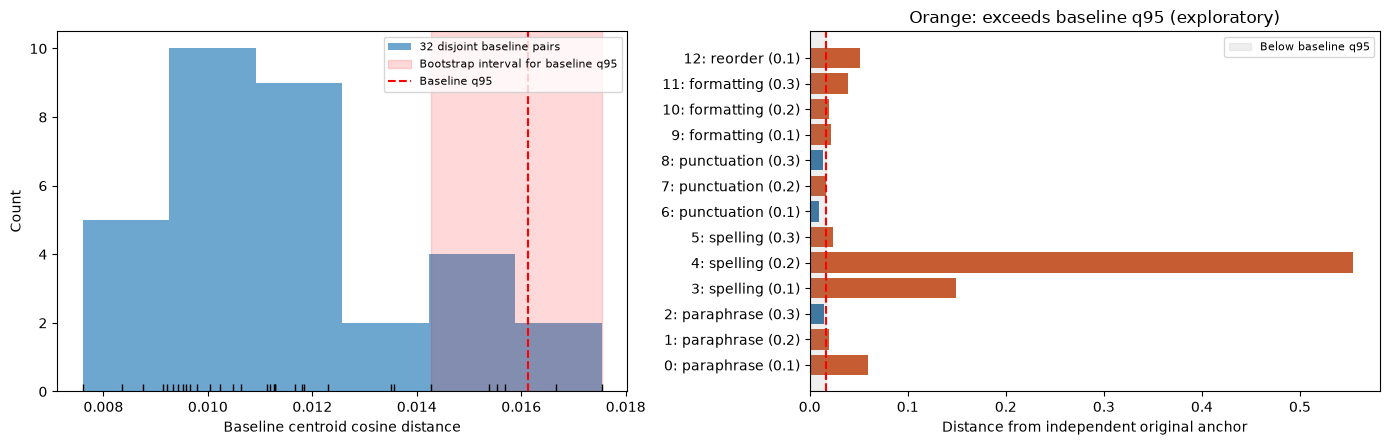

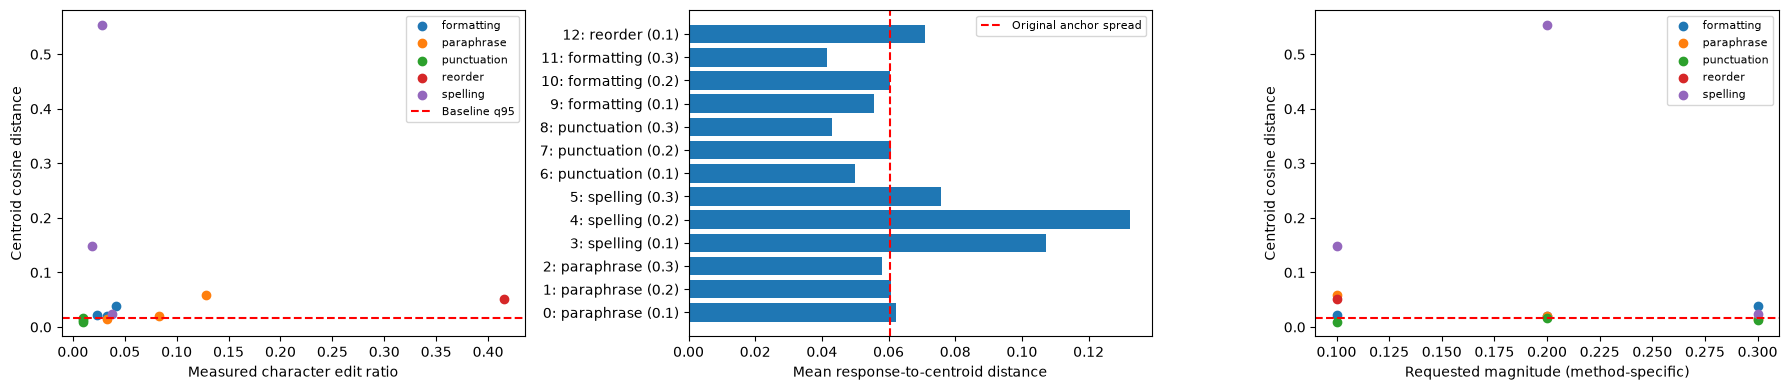

,label,distance,baseline_percentile,median_ratio,upper_tail_fraction,exceeds_q95
0,0: paraphrase (0.1),0.059289,100.000,5.313735,0.030303,True
1,1: paraphrase (0.2),0.019350,100.000,1.734234,0.030303,True
2,2: paraphrase (0.3),0.014440,84.375,1.294157,0.181818,False
3,3: spelling (0.1),0.149125,100.000,13.365254,0.030303,True
4,4: spelling (0.2),0.553961,100.000,49.648521,0.030303,True
5,5: spelling (0.3),0.023980,100.000,2.149219,0.030303,True
6,6: punctuation (0.1),0.009802,34.375,0.878466,0.666667,False
7,7: punctuation (0.2),0.016266,93.750,1.457842,0.090909,True
8,8: punctuation (0.3),0.013397,75.000,1.200692,0.272727,False
9,9: formatting (0.1),0.021433,100.000,1.920895,0.030303,True


Independent baseline pairs:   0%|          | 0/32 [00:00<?, ?it/s]

Independent baseline pairs:   3%|▎         | 1/32 [00:00<00:03,  8.24it/s]

Independent baseline pairs:   6%|▋         | 2/32 [00:00<00:03,  8.12it/s]

Independent baseline pairs:   9%|▉         | 3/32 [00:00<00:03,  8.01it/s]

Independent baseline pairs:  12%|█▎        | 4/32 [00:00<00:03,  7.83it/s]

... (40 outputs left out)

Robustness ensembles:  85%|████████▍ | 11/13 [00:01<00:00,  8.88it/s]

Robustness ensembles:  92%|█████████▏| 12/13 [00:01<00:00,  8.82it/s]

Robustness ensembles: 100%|██████████| 13/13 [00:01<00:00,  8.81it/s]

Robustness ensembles: 100%|██████████| 13/13 [00:01<00:00,  9.10it/s]

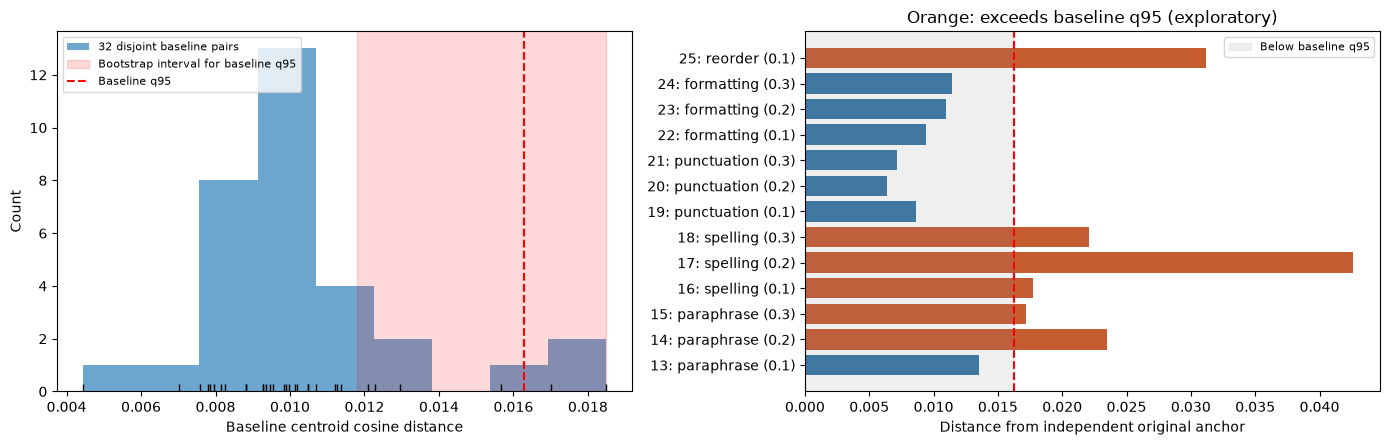

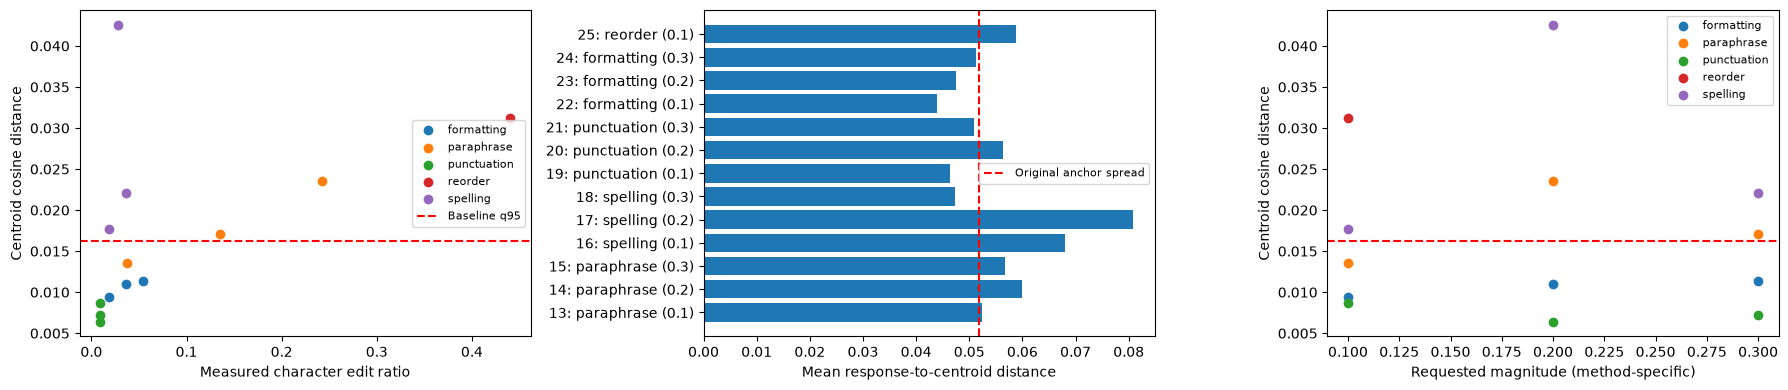

,label,distance,baseline_percentile,median_ratio,upper_tail_fraction,exceeds_q95
0,13: paraphrase (0.1),0.013546,90.625,1.372470,0.121212,False
1,14: paraphrase (0.2),0.023496,100.000,2.380565,0.030303,True
2,15: paraphrase (0.3),0.017146,96.875,1.737147,0.060606,True
3,16: spelling (0.1),0.017692,96.875,1.792464,0.060606,True
4,17: spelling (0.2),0.042571,100.000,4.313152,0.030303,True
5,18: spelling (0.3),0.022061,100.000,2.235195,0.030303,True
6,19: punctuation (0.1),0.008671,25.000,0.878547,0.757576,False
7,20: punctuation (0.2),0.006413,3.125,0.649753,0.969697,False
8,21: punctuation (0.3),0.007177,6.250,0.727155,0.939394,False
9,22: formatting (0.1),0.009377,40.625,0.950061,0.606061,False


In [7]:
started=time.perf_counter(); robustness=[]
for pi,prompt in enumerate(prompts):
    selected=perturbations[(perturbations.prompt_id==pi)&perturbations.include]
    ref,anchor,base_spread,base_E=baseline(prompt)
    rows=[]
    for idx,row in tqdm(selected.iterrows(),total=len(selected),desc='Robustness ensembles'):
        role='robustness/'+digest([row.edited,row.method,row.magnitude])
        seeds=response_seeds(prompt,role)
        center,spread,E=ensemble(row.edited,role,seeds)
        result={'label':f'{idx}: {row.method} ({row.magnitude:g})','prompt_id':pi,'method':row.method,
                'magnitude':row.magnitude,'edit_ratio':row.edit_ratio,'within_spread':spread,
                'baseline_spread':base_spread,**effect_stats(cosine_distance(center,anchor),ref)}
        if cfg.paired_sampling:
            paired,_,_=ensemble(prompt,role+'/paired-original',seeds)
            result['paired_distance']=cosine_distance(center,paired)
        rows.append(result)
        pd.DataFrame(robustness+rows).to_csv(OUT/'robustness.csv',index=False)
    if not rows: continue
    frame=pd.DataFrame(rows); robustness.extend(rows)
    comparison_plot(ref,frame,f'robustness_{pi}.png')
    fig,axs=plt.subplots(1,3,figsize=(18,4))
    for method,group in frame.groupby('method'):
        axs[0].scatter(group.edit_ratio,group.distance,label=method)
        axs[2].scatter(group.magnitude,group.distance,label=method)
    axs[0].axhline(np.quantile(ref,.95),color='red',ls='--',label='Baseline q95')
    axs[0].set(xlabel='Measured character edit ratio',ylabel='Centroid cosine distance'); axs[0].legend(fontsize=8)
    axs[1].barh(frame.label,frame.within_spread)
    axs[1].axvline(base_spread,ls='--',color='red',label='Original anchor spread')
    axs[1].set(xlabel='Mean response-to-centroid distance'); axs[1].legend(fontsize=8)
    axs[2].axhline(np.quantile(ref,.95),color='red',ls='--')
    axs[2].set(xlabel='Requested magnitude (method-specific)',ylabel='Centroid cosine distance')
    axs[2].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUT/f'robustness_spread_{pi}.png'); plt.show()
    display(frame[['label','distance','baseline_percentile','median_ratio','upper_tail_fraction','exceeds_q95']])
perturbations.to_csv(OUT/'included_perturbations.csv',index=False)
status['robustness']='EXECUTED' if robustness else 'NO VALID VARIANTS'
timings['robustness_including_baselines_seconds']=time.perf_counter()-started
atomic_json(OUT/'timings.json',timings)

## 2b · Separate robustness experiment: prompt padding
[Himelstein et al., *Silent Tokens, Loud Effects: Padding in LLMs*, §3](https://arxiv.org/html/2510.01238v2) prepend actual pad-token IDs and intentionally mark them as attended inputs to simulate a masking error. We adapt that manipulation to this notebook's **MiniLM response-centroid cosine distance**, rather than reproducing the paper's activation, generation-quality, bias or safety evaluations. Qwen3-0.6B is our existing model; this is not a replication of the paper's model suite.

The same chat-formatted prompt and short-answer instruction are used in three conditions:
- **Zero padding:** a fresh independent response ensemble, not the anchor and not forced to zero displacement.
- **Masked padding:** prepend k tokenizer pad IDs, mask them out, and keep the real tokens' position IDs unchanged. This is the implementation control.
- **Attended padding:** prepend the same k IDs with attention-mask entries of one. Their positions count as real inputs, simulating the masking mistake.

Padding is inserted **before the entire tokenized chat template**, not as the text `[PAD]`, spaces, or irrelevant prose. We do not right-pad decoder inputs or alter weights. The tokenizer pad ID and its relation to EOS/BOS are recorded: special tokens are not semantically neutral when deliberately attended.

Extended mode uses k = 0, 1, 2, 4, 8, 16, 32, 128; fast mode uses 0, 1, 8, 32. Set `padding_enabled=False` to skip this section. Each condition uses the current ensemble size and temperature. Distinct reproducible seeds preserve independent sampling. Baselines and anchors are reused only for the identical original prompt and settings. Correctly masked padding may still yield nonzero *independently sampled* centroid displacement. A same-input next-token-logit check separately tests masking and position alignment.

An empty answer, generation-cap cutoff, or response exceeding the encoder context is **saved and counted as a failed sample**, not silently retried, truncated or replaced. If any sample in a condition fails, its full-ensemble semantic distance is reported as unavailable; the failure-rate plot remains meaningful. Threshold exceedances remain exploratory, with the same sampling and multiple-comparison caveats as Section 2.


additional_responses                                                    360
estimated_cold_minutes                                            21.856452
note                      Uses the local generation profile; cache reuse...
dtype: object

Padding prompt 0:   0%|          | 0/15 [00:00<?, ?it/s]

Padding prompt 0:  73%|███████▎  | 11/15 [00:00<00:00, 98.80it/s]

Padding prompt 0: 100%|██████████| 15/15 [00:00<00:00, 85.56it/s]

,label,prompt_id,pad_count,mask_mode,samples,failed_samples,failure_rate,distance,within_spread,baseline_q95,metric_status,baseline_median,baseline_percentile,upper_tail_fraction,median_ratio,exceeds_q95
0,unpadded: 0 pads,0,0,unpadded,12,0,0.0,0.015348,0.045390,0.016133,complete,0.011158,84.375,0.181818,1.375543,False
1,masked: 1 pads,0,1,masked,12,0,0.0,0.010894,0.056053,0.016133,complete,0.011158,46.875,0.545455,0.976412,False
2,attended: 1 pads,0,1,attended,12,0,0.0,0.015273,0.090965,0.016133,complete,0.011158,84.375,0.181818,1.368828,False
3,masked: 2 pads,0,2,masked,12,0,0.0,0.011046,0.052897,0.016133,complete,0.011158,46.875,0.545455,0.989949,False
4,attended: 2 pads,0,2,attended,12,0,0.0,0.009662,0.045685,0.016133,complete,0.011158,31.250,0.696970,0.865918,False
5,masked: 4 pads,0,4,masked,12,0,0.0,0.012908,0.057277,0.016133,complete,0.011158,75.000,0.272727,1.156877,False
6,attended: 4 pads,0,4,attended,12,0,0.0,0.017961,0.057353,0.016133,complete,0.011158,100.000,0.030303,1.609743,True
7,masked: 8 pads,0,8,masked,12,0,0.0,0.011690,0.067573,0.016133,complete,0.011158,65.625,0.363636,1.047670,False
8,attended: 8 pads,0,8,attended,12,0,0.0,0.036008,0.030832,0.016133,complete,0.011158,100.000,0.030303,3.227167,True
9,masked: 16 pads,0,16,masked,12,0,0.0,0.008431,0.043140,0.016133,complete,0.011158,6.250,0.939394,0.755626,False


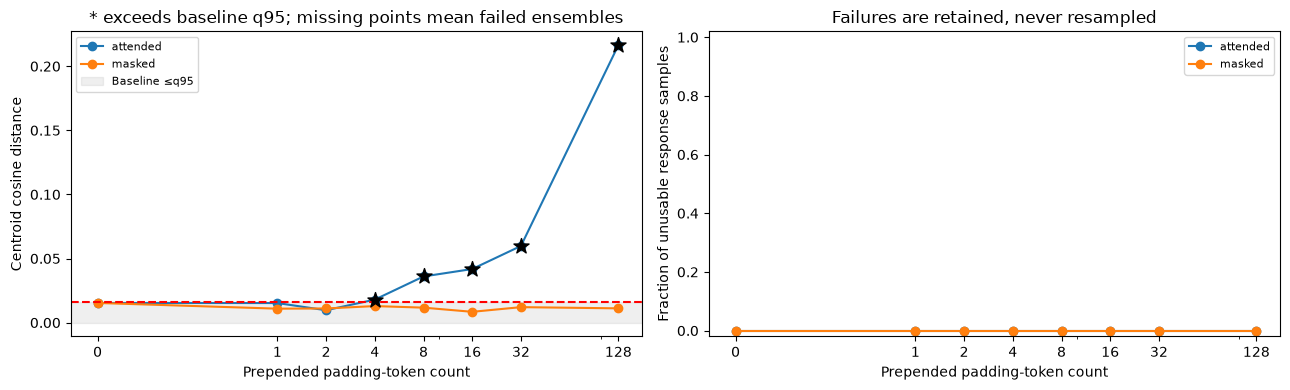

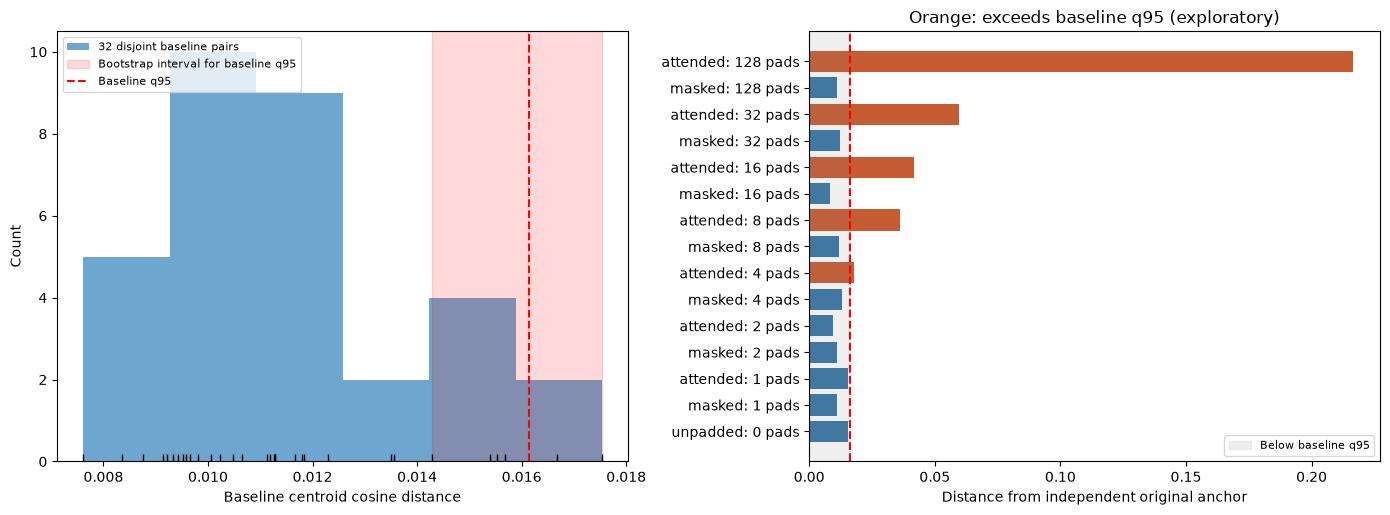

Padding prompt 1:   0%|          | 0/15 [00:00<?, ?it/s]

Padding prompt 1:  40%|████      | 6/15 [00:00<00:00, 49.22it/s]

Padding prompt 1:  73%|███████▎  | 11/15 [00:00<00:00, 45.36it/s]

Padding prompt 1: 100%|██████████| 15/15 [00:00<00:00, 43.46it/s]

,label,prompt_id,pad_count,mask_mode,samples,failed_samples,failure_rate,distance,within_spread,baseline_q95,metric_status,baseline_median,baseline_percentile,upper_tail_fraction,median_ratio,exceeds_q95
0,unpadded: 0 pads,1,0,unpadded,12,0,0.000000,0.010759,0.046852,0.016278,complete,0.00987,71.875,0.303030,1.090026,False
1,masked: 1 pads,1,1,masked,12,0,0.000000,0.011178,0.053925,0.016278,complete,0.00987,71.875,0.303030,1.132499,False
2,attended: 1 pads,1,1,attended,12,0,0.000000,0.011568,0.048095,0.016278,complete,0.00987,81.250,0.212121,1.172012,False
3,masked: 2 pads,1,2,masked,12,0,0.000000,0.007056,0.050763,0.016278,complete,0.00987,6.250,0.939394,0.714920,False
4,attended: 2 pads,1,2,attended,12,0,0.000000,0.009070,0.046940,0.016278,complete,0.00987,31.250,0.696970,0.918960,False
5,masked: 4 pads,1,4,masked,12,0,0.000000,0.007448,0.048306,0.016278,complete,0.00987,6.250,0.939394,0.754663,False
6,attended: 4 pads,1,4,attended,12,0,0.000000,0.011253,0.048548,0.016278,complete,0.00987,78.125,0.242424,1.140090,False
7,masked: 8 pads,1,8,masked,12,0,0.000000,0.010053,0.049043,0.016278,complete,0.00987,56.250,0.454545,1.018531,False
8,attended: 8 pads,1,8,attended,12,0,0.000000,0.019149,0.047135,0.016278,complete,0.00987,100.000,0.030303,1.940105,True
9,masked: 16 pads,1,16,masked,12,0,0.000000,0.008520,0.054611,0.016278,complete,0.00987,25.000,0.757576,0.863226,False


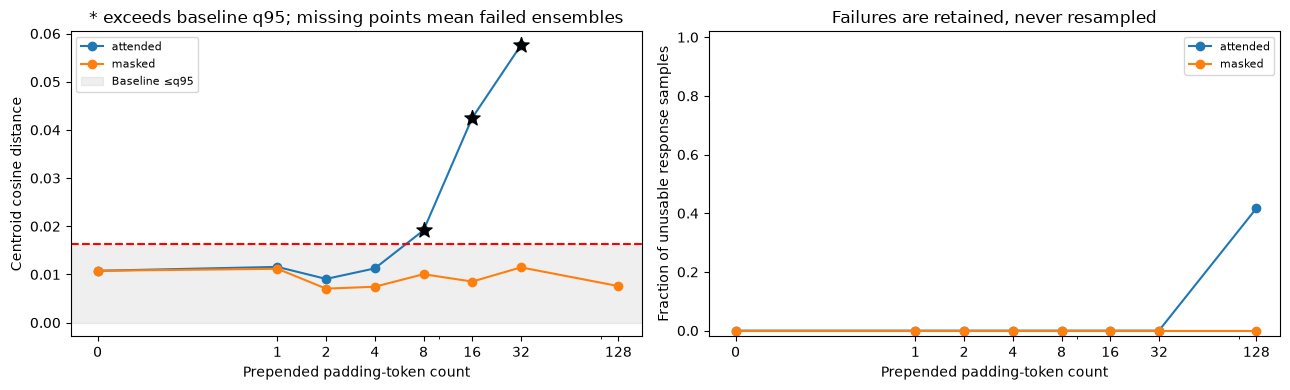

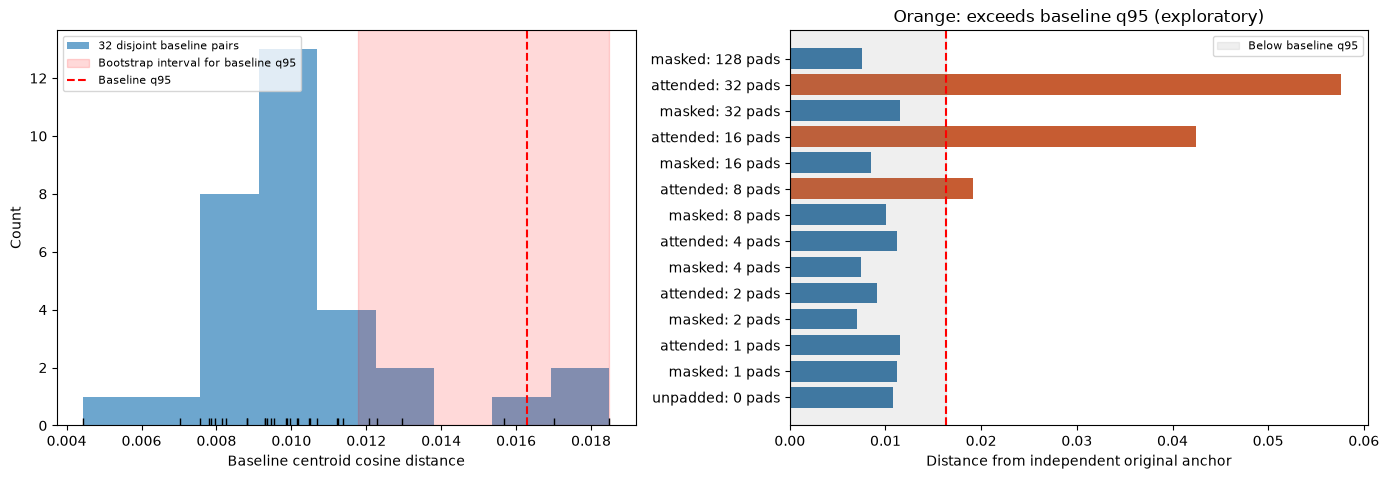

,prompt_id,mask_mode,pad_count,response,issues
0,0,unpadded,0,"Smaller metal grains increase strength by improving the material's microstructure and allowing for more dislocations to move freely. However, the limitation...",[]
156,0,masked,128,Making metal grains smaller increases strength by reducing the amount of dislocation that can move. One limitation is the risk of brittle fracture if the gr...,[]
168,0,attended,128,"The presence of metal grains can decrease the strength of the material, as they can create cracks and fractures, making the material more brittle and less r...",[]
180,1,unpadded,0,"Temperature affects atomic diffusion in solids by increasing the kinetic energy of atoms, enhancing their movement and interaction. This facilitates the tra...",[]
336,1,masked,128,"Temperature affects atomic diffusion in solids by increasing the rate of atom movement through the lattice, facilitating the transfer of atoms. This is cruc...",[]
348,1,attended,128,"The increase in temperature during heat treatment affects atomic diffusion in a solid by increasing the thermal energy. As temperature increases, the atomic...",[]


In [8]:
def prepare_padded_inputs(prompt, count, mode):
    if count < 0 or mode not in {'masked','attended'}: raise ValueError('Invalid padding condition')
    t=backend.torch; tok=backend.tokenizer
    if tok.pad_token_id is None: raise ValueError('Tokenizer has no pad token; do not silently substitute EOS')
    text=tok.apply_chat_template([{'role':'user','content':prompt}],tokenize=False,
                                add_generation_prompt=True,enable_thinking=False)
    original=tok(text,return_tensors='pt',add_special_tokens=False).input_ids.to(cfg.device)
    if original.shape[1]+count+cfg.max_new_tokens > backend.model.config.max_position_embeddings:
        raise ValueError('Padded prompt plus generation budget exceeds model context')
    pads=t.full((1,count),tok.pad_token_id,dtype=original.dtype,device=original.device)
    ids=t.cat([pads,original],dim=1)
    mask=t.ones_like(ids)
    if mode=='masked': mask[:,:count]=0
    positions=(mask.cumsum(-1)-1).clamp(min=0)
    positions.masked_fill_(mask==0,0)
    return {'input_ids':ids,'attention_mask':mask,'position_ids':positions}

def padding_identity(prompt,seed,count,mode):
    return {**request_identity(prompt,seed,cfg.temperature),'padding_revision':'left-pad-v1',
            'pad_count':count,'mask_mode':mode if count else 'unpadded',
            'pad_token_id':backend.tokenizer.pad_token_id,'position_policy':'attention-mask-cumsum'}

def cached_padding_generate(prompt,seed,count,mode):
    request=padding_identity(prompt,seed,count,mode); key=digest(request)
    path=CACHE/(key+'.padding_response.json')
    if path.exists():
        saved=json.loads(path.read_text())
        if saved['request']!=request: raise RuntimeError('Invalid padding checkpoint')
        cache_stats['generation_hits']+=1; generation_events.append({'key':key,'cache_hit':True,'seconds':0,'experiment':'padding'})
        return saved
    budget_check(); started=time.perf_counter(); t=backend.torch; tok=backend.tokenizer
    x=prepare_padded_inputs(prompt,count,mode)
    t.manual_seed(int(seed))
    if cfg.device=='mps': t.mps.manual_seed(int(seed))
    with t.inference_mode():
        y=backend.model.generate(**x,do_sample=True,temperature=cfg.temperature,top_p=1.,top_k=0,
                                 max_new_tokens=cfg.max_new_tokens,pad_token_id=tok.eos_token_id)
    new=y[0,x['input_ids'].shape[1]:]
    eos=backend.model.generation_config.eos_token_id
    eos=[eos] if isinstance(eos,int) else (eos or [])
    text=tok.decode(new,skip_special_tokens=True).strip()
    capped=len(new)>=cfg.max_new_tokens and int(new[-1]) not in eos
    encoder_length=len(encoder.tokenizer(text,truncation=False)['input_ids'])
    issues=[]
    if not text: issues.append('empty')
    if capped: issues.append('generation_cap')
    if encoder_length>encoder.max_seq_length: issues.append('encoder_context')
    saved={'request':request,'text':text,'seconds':time.perf_counter()-started,
           'generated_tokens':len(new),'encoder_tokens':encoder_length,'issues':issues,
           'input_tokens':x['input_ids'].shape[1],'attended_input_tokens':int(x['attention_mask'].sum())}
    atomic_json(path,saved); cache_stats['generation_misses']+=1
    generation_events.append({'key':key,'cache_hit':False,'seconds':saved['seconds'],'experiment':'padding'})
    atomic_json(OUT/'generation_events.json',generation_events)
    return saved

def check_padding_alignment(prompt):
    t=backend.torch; actual=prompt+'\n\n'+cfg.response_instruction
    zero=prepare_padded_inputs(actual,0,'masked')
    count=max(cfg.padding_counts); masked=prepare_padded_inputs(actual,count,'masked')
    attended=prepare_padded_inputs(actual,count,'attended')
    assert t.equal(masked['input_ids'][:,count:],zero['input_ids'])
    assert t.equal(masked['position_ids'][:,count:],zero['position_ids'])
    assert int(masked['attention_mask'][:,:count].sum())==0
    assert int(attended['attention_mask'].sum())==attended['input_ids'].shape[1]
    assert t.equal(attended['position_ids'][:,count:],zero['position_ids']+count)
    with t.inference_mode():
        z=backend.model(**zero,use_cache=False).logits[0,-1].float()
        m=backend.model(**masked,use_cache=False).logits[0,-1].float()
    t.testing.assert_close(z,m,rtol=1e-4,atol=1e-3)
    return {'prompt_digest':digest(prompt),'checked_pad_count':count,'max_abs_logit_difference':float((z-m).abs().max()),
            'top_token_equal':bool(z.argmax()==m.argmax()),'masked_positions_preserved':True,'input_suffix_preserved':True}

padding_rows=[]; padding_records=[]
if cfg.padding_enabled:
    if weight_state!='original': raise RuntimeError('Padding must run on restored original weights')
    started=time.perf_counter()
    audit=[check_padding_alignment(prompt) for prompt in prompts]
    atomic_json(OUT/'padding_alignment.json',audit)
    atomic_json(OUT/'padding_token_info.json',{'pad_id':backend.tokenizer.pad_token_id,
        'pad_token':backend.tokenizer.pad_token,'eos_ids':backend.model.generation_config.eos_token_id,
        'bos_id':backend.model.generation_config.bos_token_id,'insertion':'before full chat template'})
    conditions=[(0,'unpadded')]+[(k,mode) for k in sorted(cfg.padding_counts) if k>0 for mode in cfg.padding_modes]
    padding_estimate={'additional_responses':len(prompts)*len(conditions)*cfg.ensemble_size,
        'estimated_cold_minutes':1.5*len(prompts)*len(conditions)*cfg.ensemble_size*seconds_per_response/60,
        'note':'Uses the local generation profile; cache reuse reduces actual time. Included in total notebook estimate.'}
    atomic_json(OUT/'padding_runtime_estimate.json',padding_estimate); display(pd.Series(padding_estimate))
    for pi,prompt in enumerate(prompts):
        ref,anchor,_,_=baseline(prompt); per_prompt=[]
        for count,mode in tqdm(conditions,desc=f'Padding prompt {pi}'):
            role=f'padding/{count}/{mode}'
            seeds=response_seeds(prompt,role); texts=[]; failed=0
            for seed in seeds:
                actual=prompt+'\n\n'+cfg.response_instruction
                result=cached_padding_generate(actual,seed,count,'masked' if count==0 else mode)
                texts.append(result['text']); failed+=bool(result['issues'])
                record={'prompt_id':pi,'prompt':prompt,'label':role,'pad_count':count,'mask_mode':mode,
                        'seed':int(seed),'response':result['text'],'issues':result['issues'],
                        'generated_tokens':result['generated_tokens'],'encoder_tokens':result['encoder_tokens']}
                padding_records.append(record); atomic_json(OUT/'padding_responses.json',padding_records)
            row={'label':f'{mode}: {count} pads','prompt_id':pi,'pad_count':count,'mask_mode':mode,
                 'samples':len(seeds),'failed_samples':failed,'failure_rate':failed/len(seeds),
                 'distance':None,'within_spread':None,'baseline_q95':float(np.quantile(ref,.95)),
                 'metric_status':'unavailable: incomplete ensemble' if failed else 'complete'}
            if not failed:
                E=encode(texts); embeddings.append((f'padding/{pi}/{count}/{mode}',E)); center=E.mean(axis=0)
                row.update(effect_stats(cosine_distance(center,anchor),ref))
                row['within_spread']=float(np.mean([cosine_distance(e,center) for e in E]))
            per_prompt.append(row); padding_rows.append(row)
            pd.DataFrame(padding_rows).to_csv(OUT/'padding.csv',index=False)
        frame=pd.DataFrame(per_prompt); display(frame)
        fig,axs=plt.subplots(1,2,figsize=(13,4))
        zero=frame[frame.pad_count==0].iloc[0]
        for mode,group in frame[frame.pad_count>0].groupby('mask_mode'):
            group=group.sort_values('pad_count')
            xs=[0]+group.pad_count.tolist(); ys=[zero.distance]+group.distance.tolist()
            axs[0].plot(xs,ys,'o-',label=mode)
            above=group[group.distance>group.baseline_q95]
            axs[0].scatter(above.pad_count,above.distance,marker='*',s=130,color='black',zorder=4)
            axs[1].plot(xs,[zero.failure_rate]+group.failure_rate.tolist(),'o-',label=mode)
        axs[0].axhspan(0,np.quantile(ref,.95),color='grey',alpha=.12,label='Baseline ≤q95')
        axs[0].axhline(np.quantile(ref,.95),color='red',ls='--')
        for ax in axs:
            ax.set_xscale('symlog',linthresh=1); ax.set_xlim(-.15,max(1,max(cfg.padding_counts)*1.4)); ax.set_xticks(sorted(cfg.padding_counts),labels=sorted(cfg.padding_counts))
            ax.set_xlabel('Prepended padding-token count'); ax.legend(fontsize=8)
        axs[0].set(ylabel='Centroid cosine distance',title='* exceeds baseline q95; missing points mean failed ensembles')
        axs[1].set(ylabel='Fraction of unusable response samples',ylim=(-.02,1.02),title='Failures are retained, never resampled')
        fig.tight_layout(); fig.savefig(OUT/f'padding_{pi}.png'); plt.show()
        valid=frame[frame.metric_status=='complete']
        if len(valid): comparison_plot(ref,valid,f'padding_baseline_{pi}.png')
    examples=pd.DataFrame(padding_records)
    examples=examples[examples.pad_count.isin([0,max(cfg.padding_counts)])].groupby(['prompt_id','mask_mode','pad_count'],sort=False).head(1)
    with pd.option_context('display.max_colwidth',160):
        display(examples[['prompt_id','mask_mode','pad_count','response','issues']])
    timings['padding_seconds']=time.perf_counter()-started
    status['padding']='EXECUTED; consult failure rates for unavailable semantic distances'
    atomic_json(OUT/'timings.json',timings)
else: status['padding']='SKIPPED by configuration'


## 3 · Stability: a reversible random weight plane
For each unique floating-point parameter tensor W, draw independent Gaussian directions D₁, D₂ and scale each to ||W||₂. The plane is W + αD₁ + βD₂. Directions are reproducible, tensor-normalized, and not assumed exactly orthogonal. Zero-norm tensors remain unchanged; tied parameters are visited once. The coordinates are relative per-tensor perturbation scales, not percentages of semantic change.

The implementation keeps an exact CPU copy of the original parameters and recreates directions deterministically one tensor at a time. Every grid point starts from that copy; a `finally` block restores and checks exact equality even if generation fails. There is no cumulative add/subtract drift. Memory still includes the original model, one full CPU copy, and temporary tensors. A parameter-count guard blocks large models. Hard process termination cannot run Python cleanup; reload the original checkpoint after a kernel crash. Nothing writes modified weights to the installed checkpoint.

Use a small floating-point causal language model. This measures local parameter sensitivity, **not reproducibility of training**. The center cell uses a fresh ensemble and need not have zero distance from the separately sampled original anchor.

Baseline pairs and the original anchor are reused from robustness only for the identical fixed prompt and settings. Each grid point has distinct reproducible sampling seeds, including the original center. Checkpoint hits skip generation and unnecessary weight mutation; restoration checks are still recorded. If a time-budget or generation error interrupts a point, `finally` restores the original weights.

Weight plane rows:   0%|          | 0/3 [00:00<?, ?it/s]

Weight plane rows:  33%|███▎      | 1/3 [00:00<00:01,  1.40it/s]

Weight plane rows:  67%|██████▋   | 2/3 [00:01<00:00,  1.50it/s]

Weight plane rows: 100%|██████████| 3/3 [00:01<00:00,  1.54it/s]

Weight plane rows: 100%|██████████| 3/3 [00:01<00:00,  1.52it/s]

,label,alpha,beta,within_spread,point_seconds,distance,baseline_median,baseline_q95,baseline_percentile,upper_tail_fraction,median_ratio,exceeds_q95
0,"(-0.005, -0.005)",-0.005,-0.005,0.058407,0.306040,0.016357,0.011158,0.016133,93.750,0.090909,1.465967,True
1,"(0, -0.005)",0.000,-0.005,0.065455,0.204505,0.011794,0.011158,0.016133,65.625,0.363636,1.057072,False
2,"(0.005, -0.005)",0.005,-0.005,0.062787,0.202035,0.011141,0.011158,0.016133,50.000,0.515152,0.998539,False
3,"(-0.005, 0)",-0.005,0.000,0.069699,0.207962,0.019087,0.011158,0.016133,100.000,0.030303,1.710659,True
4,"(0, 0)",0.000,0.000,0.053501,0.208866,0.010865,0.011158,0.016133,46.875,0.545455,0.973747,False
5,"(0.005, 0)",0.005,0.000,0.046625,0.212291,0.011977,0.011158,0.016133,71.875,0.303030,1.073456,False
6,"(-0.005, 0.005)",-0.005,0.005,0.068278,0.213641,0.015992,0.011158,0.016133,93.750,0.090909,1.433295,False
7,"(0, 0.005)",0.000,0.005,0.053992,0.202940,0.011329,0.011158,0.016133,62.500,0.393939,1.015356,False
8,"(0.005, 0.005)",0.005,0.005,0.046206,0.207265,0.014832,0.011158,0.016133,84.375,0.181818,1.329329,False


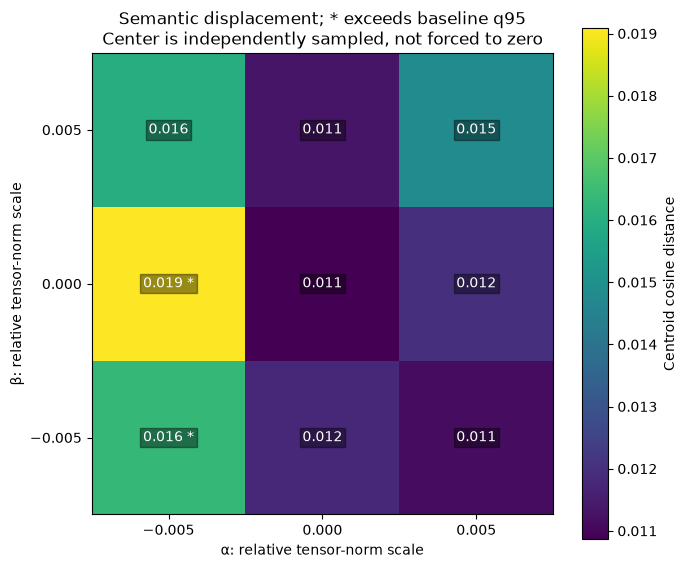

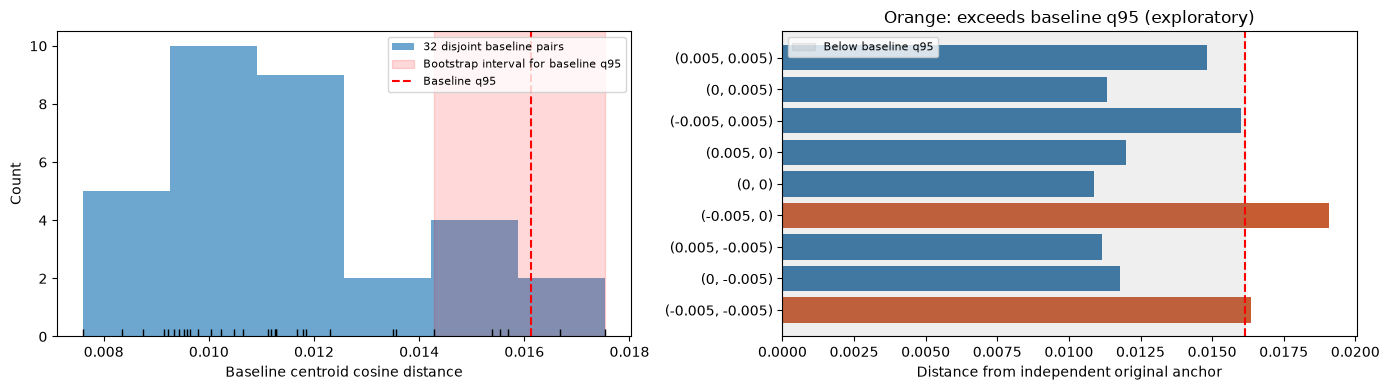

In [9]:
class WeightPlane:
    def __init__(self, model, seed, max_parameters):
        import torch
        self.torch=torch; self.model=model; self.seed=seed
        self.params=list(model.named_parameters())
        if sum(p.numel() for _,p in self.params)>max_parameters:
            raise ValueError('Model exceeds plane memory guard; use a smaller local checkpoint')
        if any(not p.is_floating_point() for _,p in self.params):
            raise ValueError('Random plane requires floating-point parameters')
        self.original={name:p.detach().cpu().clone() for name,p in self.params}
    def direction(self, base, index, axis):
        t=self.torch; g=t.Generator(device='cpu').manual_seed(self.seed+2*index+axis)
        d=t.randn(base.shape,generator=g,dtype=t.float32)
        norm=d.norm()
        if norm>0: d.mul_(base.float().norm()/norm)
        return d
    def restore(self):
        with self.torch.no_grad():
            for name,p in self.params: p.copy_(self.original[name].to(p.device))
        for name,p in self.params:
            if not self.torch.equal(p.detach().cpu(),self.original[name]):
                raise RuntimeError('Weight restoration failed: '+name)
    @contextmanager
    def at(self, alpha, beta):
        try:
            with self.torch.no_grad():
                for i,(name,p) in enumerate(self.params):
                    base=self.original[name]
                    changed=base.float().clone()
                    if alpha: changed.add_(self.direction(base,i,0),alpha=float(alpha))
                    if beta: changed.add_(self.direction(base,i,1),alpha=float(beta))
                    p.copy_(changed.to(device=p.device,dtype=p.dtype))
            yield
        finally: self.restore()

stability_prompt=prompts[0]
started=time.perf_counter(); ref,anchor,spread,E=baseline(stability_prompt)
plane=WeightPlane(backend.model,cfg.seed,cfg.plane_max_parameters)
axis=np.linspace(-cfg.weight_radius,cfg.weight_radius,cfg.grid_size)
rows=[]; grid=np.zeros((len(axis),len(axis))); restore_audit=[]
try:
    for j,beta in enumerate(tqdm(axis,desc='Weight plane rows')):
        for i,alpha in enumerate(axis):
            budget_check(); point_start=time.perf_counter()
            state='original' if alpha==0 and beta==0 else digest({'plane':'tensor-normalized-v1','seed':cfg.seed,'alpha':float(alpha),'beta':float(beta)})
            role='plane/'+digest([float(alpha),float(beta),cfg.seed])
            seeds=response_seeds(stability_prompt,role)
            actual=stability_prompt+'\n\n'+cfg.response_instruction
            complete=all((CACHE/(digest(request_identity(actual,s,cfg.temperature,state))+'.response.json')).exists() for s in seeds)
            if complete:
                # No weight mutation necessary: all responses from this exact state exist.
                weight_state=state
                center,within,_=ensemble(stability_prompt,role,seeds)
                weight_state='original'; plane.restore()
            else:
                try:
                    with plane.at(alpha,beta):
                        weight_state=state
                        center,within,_=ensemble(stability_prompt,role,seeds)
                finally: weight_state='original'
            restore_audit.append({'alpha':float(alpha),'beta':float(beta),'exact_restore_verified':True,'responses_cached':complete})
            grid[j,i]=cosine_distance(center,anchor)
            result={'label':f'({alpha:.4g}, {beta:.4g})','alpha':alpha,'beta':beta,
                    'within_spread':within,'point_seconds':time.perf_counter()-point_start,
                    **effect_stats(grid[j,i],ref)}
            if cfg.paired_sampling:
                paired,_,_=ensemble(stability_prompt,role+'/paired-original',seeds)
                result['paired_distance']=cosine_distance(center,paired)
            rows.append(result)
            pd.DataFrame(rows).to_csv(OUT/'stability.csv',index=False)
            atomic_json(OUT/'restoration_audit.json',restore_audit)
finally:
    weight_state='original'; plane.restore(); del plane
frame=pd.DataFrame(rows); display(frame)
q95=np.quantile(ref,.95)
fig,ax=plt.subplots(figsize=(7,6))
step=axis[1]-axis[0]
im=ax.imshow(grid,origin='lower',extent=[axis[0]-step/2,axis[-1]+step/2,axis[0]-step/2,axis[-1]+step/2],aspect='equal')
for j,beta in enumerate(axis):
    for i,alpha in enumerate(axis):
        marker=' *' if grid[j,i]>q95 else ''
        ax.text(alpha,beta,f'{grid[j,i]:.3f}'+marker,ha='center',va='center',color='white',bbox={'facecolor':'black','alpha':.4,'pad':2})
ax.set(xticks=axis,yticks=axis,xlabel='α: relative tensor-norm scale',ylabel='β: relative tensor-norm scale',
       title='Semantic displacement; * exceeds baseline q95\nCenter is independently sampled, not forced to zero')
fig.colorbar(im,ax=ax,label='Centroid cosine distance'); fig.tight_layout(); fig.savefig(OUT/'weight_plane.png'); plt.show()
comparison_plot(ref,frame,'stability_baseline.png')
status['stability']='EXECUTED; exact weight restoration verified at every grid point'
timings['stability_seconds']=time.perf_counter()-started
atomic_json(OUT/'timings.json',timings)

## Interpretation and reproducibility
- Semantic similarity approximates meaning; a similar embedding can conceal a wrong number, negation or factual error. Inspect the saved complete responses.
- A frozen semantic encoder has its own training biases and domain limitations. Freezing makes a consistent instrument, not an unbiased one.
- Temperature controls decoding variability; it does not directly measure intrinsic model uncertainty. Compare experiments within a backend, with all decoding settings held constant.
- The baseline is conditional on the prompt, model, encoder, temperature, response length and ensemble size. Small fast-mode ensembles give noisy centroids and a very coarse reference distribution.
- Text predictability does not establish truth or training-distribution membership. These synthetic document groups cannot support population-wide claims.
- Random planes sample just two directions in a vast parameter space. This is local sensitivity, not training stability.
- These measurements probe aspects of trustworthiness, not whether a model reasons or understands.

Discussion: Which edits preserve meaning? Does a larger ensemble reduce baseline displacement? Is a low-displacement answer still scientifically wrong? How do conclusions change with a different encoder?

Optional PCA visualizations should always be labeled as projections that can distort distances; all distances here use the full embeddings.

Technical references: [Transformers local model loading](https://huggingface.co/docs/transformers/main_classes/model), [Ollama API specification](https://github.com/ollama/ollama/blob/main/docs/openapi.yaml), [Sentence Transformers model API](https://sbert.net/docs/package_reference/sentence_transformer/SentenceTransformer.html). Ollama generated-token logprobs are not a substitute for observed-document teacher forcing.

In [10]:
if embeddings:
    np.savez_compressed(OUT/'response_embeddings.npz',**{f'ensemble_{i}':E for i,(_,E) in enumerate(embeddings)})
    atomic_json(OUT/'embedding_labels.json',[label for label,_ in embeddings])
timings['session_total_seconds']=time.perf_counter()-SESSION_START
atomic_json(OUT/'status.json',status); atomic_json(OUT/'timings.json',timings)
atomic_json(OUT/'generation_events.json',generation_events); atomic_json(OUT/'cache_stats.json',cache_stats)
display(pd.Series(status,name='Execution status')); display(pd.Series(timings,name='Actual seconds'))
print('Checkpoint statistics:',cache_stats)
print('Results:',OUT.resolve())

generation                                                      READY
encoder                                                         READY
generalizability                                             EXECUTED
robustness                                                   EXECUTED
padding             EXECUTED; consult failure rates for unavailabl...
stability           EXECUTED; exact weight restoration verified at...
Name: Execution status, dtype: str

model_and_encoder_load_seconds             3.626163
perturbation_generation_seconds            0.006630
robustness_including_baselines_seconds    10.384933
padding_seconds                            1.831140
stability_seconds                          2.549523
session_total_seconds                     20.144263
Name: Actual seconds, dtype: float64

Checkpoint statistics: {'generation_hits': 2353, 'generation_misses': 0, 'embedding_hits': 198}
Results: /Users/jae3goals/Jupyter Code on Root/MSE420_1020_AI_Forensics/MSE420_AI_Forensics/demonstrations/gifters_results/20261105-112738-extended
